# 01 · Portfolio risk with multivariate EWMA

**Two-stock portfolio · MSFT + AAPL · One-day VaR and Expected Shortfall**

This notebook shows the complete workflow from adjusted historical prices to conditional covariance forecasts, monetary portfolio risk estimates, and realized losses. It is intended as a short, reproducible demonstration of the multivariate part of the project.

**Model:** EWMA conditional covariance with **Normal** standardized innovations. **Risk levels:** 95% and 99% confidence (tail probabilities 5% and 1%).

## 1. Set-up and data

The portfolio holds fixed numbers of shares; its asset weights are allowed to drift with market prices. Prices come from Yahoo Finance via `yfinance` and are adjusted historical series. The money amounts shown below are therefore **adjusted-price portfolio units**, rather than a complete real-world cash-flow accounting of dividends and corporate actions.

In [3]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Supports launching Jupyter from either the project root or notebooks/.
project_root = next(
    (path for path in (Path.cwd(), Path.cwd().parent)
     if (path / "portfolio.py").exists()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Launch Jupyter from the project root or notebooks/ directory.")
sys.path.insert(0, str(project_root))

from market_data import MarketData
from portfolio import Portfolio
import backtesting
import risk_measure
import rolling_forecast
import simulation

plt.rcParams.update({
    "figure.figsize": (10, 4),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titlesize": 13,
})

In [4]:
HOLDINGS = {"MSFT": 3, "AAPL": 2}
START_DATE = "2017-01-01"
END_DATE = "2026-11-01"  # yfinance's end date is exclusive
WINDOW_LENGTH = 750      # trading observations in each estimation window
DECAY = 0.96
ALPHAS = [0.05, 0.01]    # numerical tail probabilities

port = Portfolio(HOLDINGS)
data = MarketData.from_yfinance(port.assets, START_DATE, END_DATE)
returns = port.risk_factors(data)

if len(returns) <= WINDOW_LENGTH:
    raise ValueError("Not enough return observations for the chosen window length.")

print(f"Assets: {', '.join(port.assets)}")
print(f"Return observations: {len(returns):,}")
print(f"Sample: {returns.index.min():%Y-%m-%d} to {returns.index.max():%Y-%m-%d}")

[*********************100%***********************]  2 of 2 completed

Assets: MSFT, AAPL
Return observations: 2,470
Sample: 2017-01-04 to 2026-10-30


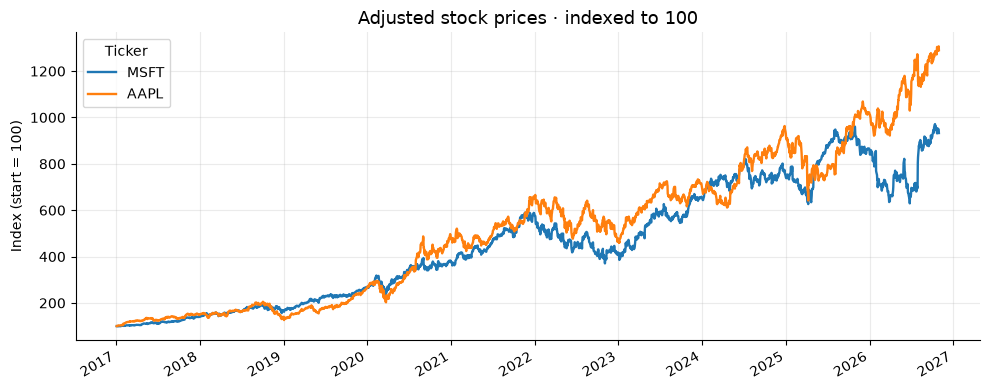

In [5]:
normalized_prices = data.prices[port.assets].div(
    data.prices[port.assets].iloc[0]
).mul(100)

ax = normalized_prices.plot(linewidth=1.7)
ax.set(title="Adjusted stock prices · indexed to 100", ylabel="Index (start = 100)", xlabel="")
plt.tight_layout()
plt.show()

## 2. Rolling covariance forecasts

EWMA updates the conditional covariance matrix using the previous return vector:

\[
\widehat\Sigma_{t\mid t-1}
=\lambda\widehat\Sigma_{t-1\mid t-2}
+(1-\lambda)X_{t-1}X_{t-1}^{\top}.
\]

At each target date, `rolling_forecast()` uses **only the preceding `WINDOW_LENGTH` observations**. The returned covariance matrices are indexed by their forecast *target* dates, so the calculation does not use realized returns from the target day.

In [10]:
forecast = rolling_forecast.rolling_forecast(
    returns,
    window_length=WINDOW_LENGTH,
    forecaster=rolling_forecast.ewma_forecaster,
    decay=DECAY,
)

print("Covariance array shape:", forecast.covariances.shape)
print("Last forecast covariance matrix:")
display(forecast.latest().round(6))

Covariance array shape: (1720, 2, 2)
Last forecast covariance matrix:


Ticker,MSFT,AAPL
Ticker,,
MSFT,0.000248,0.000001
AAPL,0.000001,0.000155


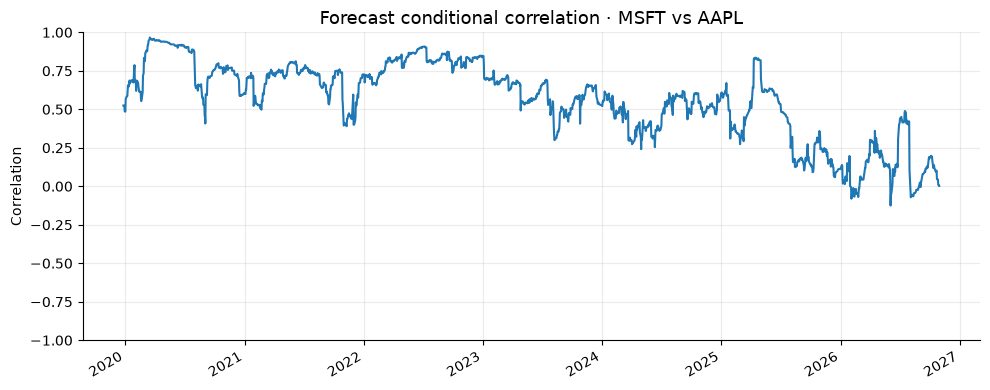

In [11]:
correlation = forecast.correlation("MSFT", "AAPL")
ax = correlation.plot(linewidth=1.5)
ax.set(
    title="Forecast conditional correlation · MSFT vs AAPL",
    ylabel="Correlation",
    xlabel="",
    ylim=(-1, 1),
)
plt.tight_layout()
plt.show()

## 3. Monetary Value at Risk and Expected Shortfall

Let \(a_{t-1}\) denote the **previous day's monetary position values**. The delta-normal approximation to one-day monetary loss variance is

\[
\widehat\sigma^2_{L,t}=a_{t-1}^{\top}\widehat\Sigma_{t\mid t-1}a_{t-1}.
\]

With standardized Normal innovation \(Z\), both risk measures scale with its conditional standard deviation:

\[
\operatorname{VaR}_{t,\alpha}=-\widehat\sigma_{L,t}\,F_Z^{-1}(\alpha),
\qquad
\operatorname{ES}_{t,\alpha}=-\widehat\sigma_{L,t}\,
\mathbb E[Z\mid Z\le F_Z^{-1}(\alpha)].
\]

The first expression is a **quantile**; the second is an **average beyond that quantile**. The separate `simulation` functions supply these standardized statistics.

In [15]:
loss_variance = port.variance_from_position_values(data, forecast)
quantiles = simulation.parametric_quantiles("Normal", ALPHAS)
tail_means = simulation.parametric_tail_means("Normal", ALPHAS)

var = risk_measure.parametric_value_at_risk(loss_variance, quantiles)
es = risk_measure.expected_shortfall(loss_variance, tail_means)
realized_losses = port.loss(data).reindex(var.index)

assert var.index.equals(es.index)
assert var.index.equals(realized_losses.index)
assert (es >= var).all().all(), "Expected Shortfall should not fall below VaR."

risk_table = pd.DataFrame({
    "Realized loss": realized_losses,
    "VaR 95%": var[0.05],
    "ES 95%": es[0.05],
    "VaR 99%": var[0.01],
    "ES 99%": es[0.01],
})

display(risk_table.tail(8).round(2))

,Realized loss,VaR 95%,ES 95%,VaR 99%,ES 99%
Date,,,,,
2026-10-21,-12.22,48.61,60.96,68.75,78.76
2026-10-22,27.15,47.96,60.14,67.83,77.71
2026-10-23,-9.31,46.97,58.90,66.43,76.11
2026-10-26,-16.63,46.38,58.17,65.60,75.16
2026-10-27,-2.57,46.35,58.13,65.55,75.10
2026-10-28,7.50,45.37,56.89,64.16,73.51
2026-10-29,-7.55,44.45,55.74,62.87,72.03
2026-10-30,33.25,43.63,54.71,61.70,70.69


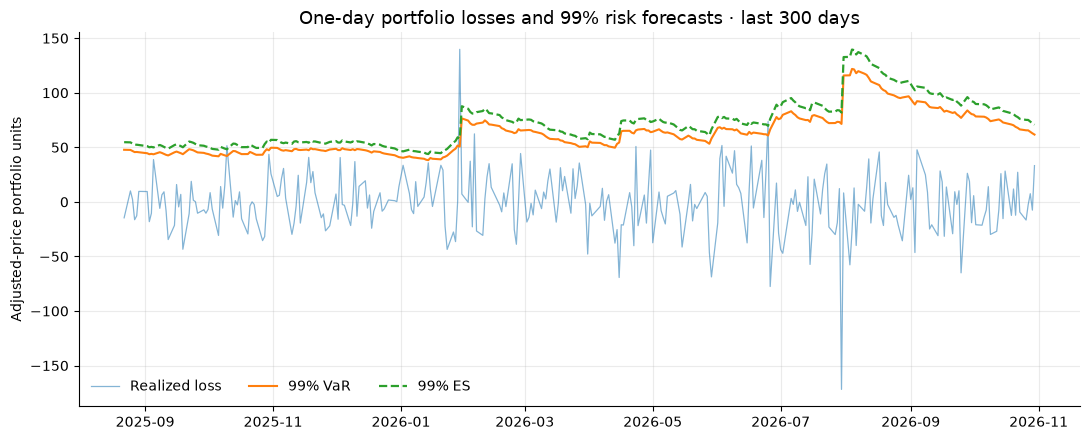

In [16]:
recent = risk_table.tail(300)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(recent.index, recent["Realized loss"], alpha=0.55, linewidth=0.9, label="Realized loss")
ax.plot(recent.index, recent["VaR 99%"], linewidth=1.5, label="99% VaR")
ax.plot(recent.index, recent["ES 99%"], linewidth=1.6, linestyle="--", label="99% ES")
ax.set(title="One-day portfolio losses and 99% risk forecasts · last 300 days",
       ylabel="Adjusted-price portfolio units", xlabel="")
ax.legend(frameon=False, ncol=3)
plt.tight_layout()
plt.show()

## 4. Interpretation

- **VaR** is the estimated one-day loss threshold; **ES** averages losses in the worst tail and therefore lies at least as high as VaR for the same tail probability.
- The changing MSFT–AAPL correlation demonstrates why a **covariance matrix**, rather than two independent volatility forecasts, matters for portfolio risk.
- Our forecast is **delta-normal**: it models a linearization of log-return P&L, while `Portfolio.loss()` evaluates realized simple-price changes.

**Scope.** This notebook demonstrates parametric EWMA/Normal forecasting, not historical simulation or Monte Carlo. The model assumes zero conditional mean and Normal standardized portfolio innovations; neither assumption is guaranteed in actual markets.